# Exploring the NYC Taxi Dataset: Source to Every Output

A detailed, visual tour of the data behind this project, built for students who are
**new to machine learning**.

We will trace one month of data through every Phase 1 transformation:

1. **Official source** and local raw files.
2. **Raw schema** and the meaning of one trip row.
3. **Validation and cleaning**, including every configured rule.
4. **Demand branch**: trips to zone-hour counts to model features.
5. **Fare branch**: cleaned trips to per-trip model features.
6. **Chronological train, validation and test splits**.
7. **Persisted artifacts** and the code that consumes them.

> Run each cell with **Shift + Enter**. Read each table from left to right and
> explain what changed before moving to the next stage.

## 0. Setup

This points Python at the project so we can reuse its real data-loading code.

In [1]:
import sys
from pathlib import Path

# Make the project importable no matter where Jupyter was launched from.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import get_config

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
config = get_config()
print("Project root:", ROOT)
print("Configured period:", config.data["tlc_year"], config.data["tlc_month"])

Project root: c:\Users\chand\projects\capstone\taxi-forecasting-student
Configured period: 2024 3


## 1. Official source and local landing files

The data is the **official NYC TLC (Taxi & Limousine Commission) Trip Record
Data** — free, public, and anonymized. The project downloads one month at a time
(by default **January 2024**) plus a zone lookup table that translates numeric
location identifiers into borough, zone and service-zone labels.

| Source object | Official location | Local landing file | Format |
|---|---|---|---|
| Yellow Taxi trip records | TLC monthly trip-data CDN | `data/raw/yellow_tripdata_2024-01.parquet` | Parquet |
| Taxi zone lookup | TLC miscellaneous-data CDN | `data/raw/taxi_zone_lookup.csv` | CSV |

The exact year, month, URLs and local directories come from `config/config.yaml`.
`src/data/ingestion.py` streams downloads in 1 MiB chunks, writes a temporary
`.part` file, then renames it only after completion. Existing files are cached
unless overwrite is requested.

### Who creates and updates it, and when?

- Authorized technology providers under the Taxi & Livery Passenger
    Enhancement Programs (TPEP/LPEP) collect and submit Yellow/Green trip records
    to NYC TLC. TLC states that it did not create those submitted records and does
    not guarantee their accuracy.
- **NYC TLC publishes the files monthly**, typically with an approximately
    **two-month delay** so vendors can complete submissions.
- There is no guaranteed calendar day. TLC can correct historical files and
    standardize schemas; check the official page's download links and Errata
    before treating a cached file as the latest version.
- This project does **not** poll for new months automatically. It downloads the
    year/month selected in configuration or `TLC_TRIP_YEAR` and
    `TLC_TRIP_MONTH`. The repository default remains January 2024 until changed.

The official Yellow Taxi data dictionary documents the broader published
fields: pickup/drop-off times and zones, distance, rate and payment types,
passenger count, and itemized fare components. The project uses the eight-field
contract shown below.

In [2]:
from src.data.ingestion import load_trips, load_zone_lookup, trip_filename

year = int(config.data["tlc_year"])
month = int(config.data["tlc_month"])
trip_name = trip_filename(year, month)
trip_url = f'{config.data["base_url"].rstrip("/")}/{trip_name}'

source_inventory = pd.DataFrame([
    {
        "object": "Yellow Taxi trips",
        "official_url": trip_url,
        "local_path": str(config.raw_dir / trip_name),
        "format": "Parquet",
    },
    {
        "object": "Taxi zones",
        "official_url": config.data["zone_lookup_url"],
        "local_path": str(config.raw_dir / "taxi_zone_lookup.csv"),
        "format": "CSV",
    },
])
source_inventory

,object,official_url,local_path,format
0,Yellow Taxi trips,https://d37ci6vzurychx.cloudfront.net/trip-dat...,C:\Users\chand\projects\capstone\taxi-forecast...,Parquet
1,Taxi zones,https://d37ci6vzurychx.cloudfront.net/misc/tax...,C:\Users\chand\projects\capstone\taxi-forecast...,CSV


In [ ]:
publication_responsibility = pd.DataFrame([
    ("Collection and provider delivery", "Authorized TPEP/LPEP technology providers", "Continuous operational submissions"),
    ("Public file publication", "NYC Taxi and Limousine Commission", "Monthly, typically about two months after the trip month"),
    ("Corrections/schema updates", "NYC Taxi and Limousine Commission", "As needed; review official Errata and metadata"),
    ("Project download selection", "Repository operator/instructor", f"Configured snapshot: {year}-{month:02d}; not automatically advanced"),
], columns=["responsibility", "owner", "cadence"])
publication_responsibility

### Load the raw inputs

The notebook expects the files to have been downloaded by
`python -m scripts.run_pipeline`, or cached by an earlier run. No data is
silently synthesized. **Each row in the trip Parquet is one completed trip.**

In [4]:
trip_path = config.raw_dir / trip_name
zone_path = config.raw_dir / "taxi_zone_lookup.csv"

if not trip_path.exists():
    raise FileNotFoundError(
        f"Missing {trip_path}. Run: python -m scripts.run_pipeline"
    )

raw = load_trips(trip_path)
zones = load_zone_lookup(zone_path)
print(f"This single month contains {len(raw):,} trips and {raw.shape[1]} columns.")
raw.head()

This single month contains 3,582,628 trips and 19 columns.


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,1,2024-03-01 00:18:51,2024-03-01 00:23:45,0.0,1.30,1.0,N,142,239,1,8.6,3.5,0.5,2.70,0.0,1.0,16.30,2.5,0.0
1,1,2024-03-01 00:26:00,2024-03-01 00:29:06,0.0,1.10,1.0,N,238,24,1,7.2,3.5,0.5,3.00,0.0,1.0,15.20,2.5,0.0
2,2,2024-03-01 00:09:22,2024-03-01 00:15:24,1.0,0.86,1.0,N,263,75,2,7.9,1.0,0.5,0.00,0.0,1.0,10.40,0.0,0.0
3,2,2024-03-01 00:33:45,2024-03-01 00:39:34,1.0,0.82,1.0,N,164,162,1,7.9,1.0,0.5,1.29,0.0,1.0,14.19,2.5,0.0
4,1,2024-03-01 00:05:43,2024-03-01 00:26:22,0.0,4.90,1.0,N,263,7,2,25.4,3.5,0.5,0.00,0.0,1.0,30.40,2.5,0.0


### Full raw schema, then the columns this project requires

TLC schemas can change over time, so first inspect every column actually present
in this file. The second table documents the eight columns required by this
project's validation contract.

| Column | Meaning |
|---|---|
| `tpep_pickup_datetime` | When the trip started |
| `tpep_dropoff_datetime` | When the trip ended |
| `passenger_count` | Number of riders |
| `trip_distance` | Distance in miles |
| `PULocationID` | **P**ick-**U**p zone number |
| `DOLocationID` | **D**rop-**O**ff zone number |
| `fare_amount` | Base fare (US$) — what we predict for *fare* |
| `total_amount` | Total incl. tip, tolls, fees |

In [6]:
schema = pd.DataFrame({
    "column": raw.columns,
    "dtype": raw.dtypes.astype(str).values,
    "non_null": raw.notna().sum().values,
    "null_count": raw.isna().sum().values,
    "example": [raw[col].dropna().iloc[0] if raw[col].notna().any() else None for col in raw.columns],
})
schema

,column,dtype,non_null,null_count,example
0,VendorID,int32,3582628,0,1
1,tpep_pickup_datetime,datetime64[us],3582628,0,2024-03-01 00:18:51
2,tpep_dropoff_datetime,datetime64[us],3582628,0,2024-03-01 00:23:45
3,passenger_count,float64,3156438,426190,0.0
4,trip_distance,float64,3582628,0,1.3
5,RatecodeID,float64,3156438,426190,1.0
6,store_and_fwd_flag,object,3156438,426190,N
7,PULocationID,int32,3582628,0,142
8,DOLocationID,int32,3582628,0,239
9,payment_type,int64,3582628,0,1


In [7]:
used = [
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count",
    "trip_distance", "PULocationID", "DOLocationID", "fare_amount", "total_amount",
]
raw[used].head(5)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,total_amount
0,2024-03-01 00:18:51,2024-03-01 00:23:45,0.0,1.30,142,239,8.6,16.30
1,2024-03-01 00:26:00,2024-03-01 00:29:06,0.0,1.10,238,24,7.2,15.20
2,2024-03-01 00:09:22,2024-03-01 00:15:24,1.0,0.86,263,75,7.9,10.40
3,2024-03-01 00:33:45,2024-03-01 00:39:34,1.0,0.82,164,162,7.9,14.19
4,2024-03-01 00:05:43,2024-03-01 00:26:22,0.0,4.90,263,7,25.4,30.40


### Locations are zones, not GPS

To protect privacy, pickup/drop-off are given as one of **265 zone numbers**. The
lookup table translates a number into a borough + neighbourhood.

In [8]:
print(f"{len(zones)} zones. A few examples:")
display(zones.head())
zones[zones["LocationID"].isin([4, 79, 132, 138, 230])]

265 zones. A few examples:


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


,LocationID,Borough,Zone,service_zone
3,4,Manhattan,Alphabet City,Yellow Zone
78,79,Manhattan,East Village,Yellow Zone
131,132,Queens,JFK Airport,Airports
137,138,Queens,LaGuardia Airport,Airports
229,230,Manhattan,Times Sq/Theatre District,Yellow Zone


The lookup is descriptive metadata. `PULocationID` and `DOLocationID` remain the
model keys; joining on `LocationID` adds readable labels for analysis and the
dashboard. It does not reveal exact pickup or drop-off coordinates.

## 2. Why does the data need cleaning?

Real-world data is messy. The raw file contains impossible records — negative
fares, zero passengers, 999-mile trips, even timestamps from the wrong year.
Let's *see* some of that mess.

In [10]:
print("Fare amount — notice the negative minimum and huge maximum:")
print(raw["fare_amount"].describe()[["min", "max"]])
print("\nA few clearly-bad rows (negative fares):")
raw.loc[raw["fare_amount"] < 0, used].head(3)

Fare amount — notice the negative minimum and huge maximum:
min   -800.0
max    900.0
Name: fare_amount, dtype: float64

A few clearly-bad rows (negative fares):


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,total_amount
193,2024-03-01 00:33:51,2024-03-01 00:58:25,2.0,5.93,68,80,-29.6,-34.6
258,2024-03-01 00:09:53,2024-03-01 00:11:28,3.0,0.09,237,162,-3.7,-8.7
270,2024-03-01 00:18:15,2024-03-01 00:19:56,1.0,0.03,142,142,-3.7,-8.7


The project's cleaning step validates the required schema, parses timestamps,
restricts rows to the configured month, derives trip duration, and applies the
bounds in `config/config.yaml`. The rules are displayed below before they are
applied.

In [11]:
from src.data.validation import REQUIRED_COLUMNS, clean_trips

rules = pd.DataFrame([
    ("schema", "all required columns exist", ", ".join(REQUIRED_COLUMNS)),
    ("timestamps", "pickup and drop-off are non-null and parseable", "required"),
    ("location", "pickup and drop-off zone IDs are non-null", "required"),
    ("reporting period", "pickup timestamp belongs to configured year/month", f"{year}-{month:02d}"),
    ("trip duration", "minutes between drop-off and pickup", f'{config.cleaning["min_trip_duration_min"]} to {config.cleaning["max_trip_duration_min"]}'),
    ("trip distance", "recorded miles", f'{config.cleaning["min_trip_distance"]} to {config.cleaning["max_trip_distance"]}'),
    ("fare", "base fare in dollars", f'{config.cleaning["min_fare"]} to {config.cleaning["max_fare"]}'),
    ("passengers", "recorded passenger count; null is treated as 0", f'{config.cleaning["min_passenger_count"]} to {config.cleaning["max_passenger_count"]}'),
], columns=["rule", "meaning", "accepted value"])
rules

,rule,meaning,accepted value
0,schema,all required columns exist,"tpep_pickup_datetime, tpep_dropoff_datetime, p..."
1,timestamps,pickup and drop-off are non-null and parseable,required
2,location,pickup and drop-off zone IDs are non-null,required
3,reporting period,pickup timestamp belongs to configured year/month,2024-03
4,trip duration,minutes between drop-off and pickup,1.0 to 240.0
5,trip distance,recorded miles,0.0 to 100.0
6,fare,base fare in dollars,0.0 to 500.0
7,passengers,recorded passenger count; null is treated as 0,1 to 8


In [12]:
clean, report = clean_trips(raw, config, year=year, month=month)
print(f"Before: {report.input_rows:,} trips")
print(f"After:  {report.output_rows:,} trips")
print(f"Dropped {report.total_dropped:,} bad rows. Breakdown:")
pd.Series(report.dropped).sort_values(ascending=False).to_frame("rows_dropped")

Before: 3,582,628 trips
After:  3,038,000 trips
Dropped 544,628 bad rows. Breakdown:


,rows_dropped
passenger_count_out_of_range,449283
fare_out_of_range,52512
trip_duration_out_of_range,42689
trip_distance_out_of_range,121
outside_target_period,23


## 3. Branch A: cleaned trips to hourly demand

Demand asks: **how many pickups will occur in a pickup zone during an hour?**
The aggregation keeps only pickup time and pickup zone, floors timestamps to the
hour, counts rows, then creates a complete zone-by-hour grid. Missing
combinations become zero pickups rather than disappearing.

In [13]:
from src.data.aggregation import aggregate_hourly_demand

demand = aggregate_hourly_demand(clean)
print("Each row = one (zone, hour) with its pickup count:")
demand.head(5)

Each row = one (zone, hour) with its pickup count:


,PULocationID,pickup_hour,pickup_count
0,1,2024-03-01 00:00:00,0
1,1,2024-03-01 01:00:00,0
2,1,2024-03-01 02:00:00,0
3,1,2024-03-01 03:00:00,0
4,1,2024-03-01 04:00:00,0


In [ ]:
print("Demand columns:", demand.columns.tolist())
print("Zones:", demand["PULocationID"].nunique())
print("Hours:", demand["pickup_hour"].nunique())
print("Rows (zones x hours):", len(demand))
print("Zero-pickup rows added/preserved:", int((demand["pickup_count"] == 0).sum()))

**Chart: how does demand change across the day?** Averaged over all zones and
days, we can see the daily rhythm of the city.

Highest monthly total: hour 18:00 with 213,095 accepted pickups


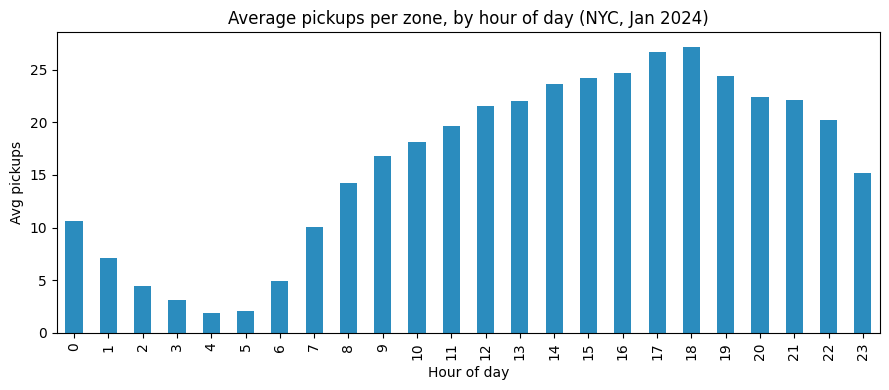

In [14]:
hourly = demand.assign(hour=demand["pickup_hour"].dt.hour).groupby("hour")["pickup_count"]
by_hour = hourly.mean()
by_hour_total = hourly.sum()
peak_hour = int(by_hour_total.idxmax())
print(f"Highest monthly total: hour {peak_hour:02d}:00 with {by_hour_total.max():,} accepted pickups")

plt.figure(figsize=(9, 4))
by_hour.plot(kind="bar", color="#2b8cbe")
plt.title("Average pickups per zone, by hour of day (NYC, Jan 2024)")
plt.xlabel("Hour of day")
plt.ylabel("Avg pickups")
plt.tight_layout()
plt.show()

**Chart: which zones are busiest?** The top pickup zones are typically Midtown
Manhattan and the airports.

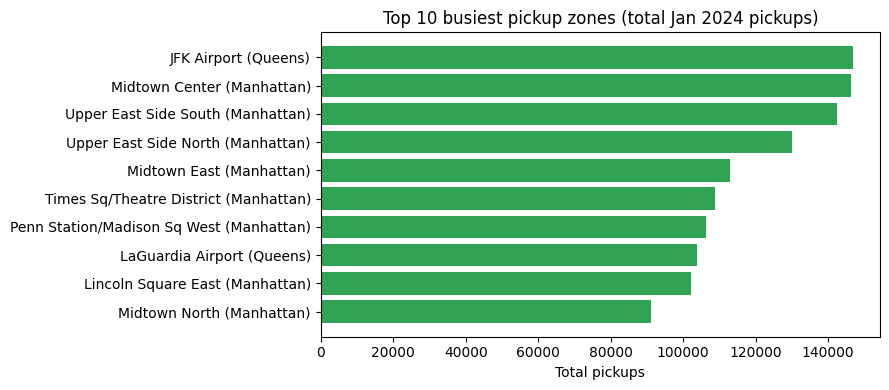

,label,pickup_count
0,JFK Airport (Queens),146945
1,Midtown Center (Manhattan),146370
2,Upper East Side South (Manhattan),142524
3,Upper East Side North (Manhattan),130076
4,Midtown East (Manhattan),112883
5,Times Sq/Theatre District (Manhattan),108878
6,Penn Station/Madison Sq West (Manhattan),106230
7,LaGuardia Airport (Queens),103684
8,Lincoln Square East (Manhattan),102208
9,Midtown North (Manhattan),91018


In [15]:
top = (
    demand.groupby("PULocationID")["pickup_count"].sum()
    .sort_values(ascending=False).head(10)
    .rename_axis("LocationID").reset_index()
    .merge(zones[["LocationID", "Zone", "Borough"]], on="LocationID", how="left")
)
top["label"] = top["Zone"] + " (" + top["Borough"] + ")"

plt.figure(figsize=(9, 4))
plt.barh(top["label"][::-1], top["pickup_count"][::-1], color="#31a354")
plt.title("Top 10 busiest pickup zones (total Jan 2024 pickups)")
plt.xlabel("Total pickups")
plt.tight_layout()
plt.show()
top[["label", "pickup_count"]]

## 4. Demand features: what the model sees

The target remains `pickup_count`. Calendar fields describe the prediction
hour. Lag fields provide earlier pickup counts from the **same zone**. Rolling
statistics summarize only earlier counts because the series is shifted by one
hour before each window is calculated. Rows without all configured lags are
dropped as a warm-up period.

In [17]:
from src.features.demand_features import build_demand_features

demand_features = build_demand_features(demand, config)
print("Configured lags:", config.features["demand_lags"])
print("Configured rolling windows:", config.features["demand_rolling_windows"])
print("Shape:", demand_features.shape)
demand_features.head()

Configured lags: [1, 2, 3, 24, 168]
Configured rolling windows: [3, 24, 168]
Shape: (145728, 23)


,PULocationID,pickup_hour,pickup_count,hour,day_of_week,month,is_weekend,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos,lag_1,lag_2,lag_3,lag_24,lag_168,rolling_mean_3,rolling_std_3,rolling_mean_24,rolling_std_24,rolling_mean_168,rolling_std_168
0,1,2024-03-08 00:00:00,0,0,4,3,0,0,0.000000,1.000000,-0.433884,-0.900969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,0.186132
1,1,2024-03-08 01:00:00,0,1,4,3,0,0,0.258819,0.965926,-0.433884,-0.900969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,0.186132
2,1,2024-03-08 02:00:00,0,2,4,3,0,0,0.500000,0.866025,-0.433884,-0.900969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,0.186132
3,1,2024-03-08 03:00:00,0,3,4,3,0,0,0.707107,0.707107,-0.433884,-0.900969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,0.186132
4,1,2024-03-08 04:00:00,0,4,4,3,0,0,0.866025,0.500000,-0.433884,-0.900969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.035714,0.186132


## 5. Branch B: cleaned trips to fare features

Here, **each cleaned trip is one training example**. The model learns how
distance, passenger count, trip duration, pickup/drop-off zones, and pickup-time
calendar signals relate to the `fare_amount` target. Unlike demand, fare is not
aggregated: one cleaned trip remains one row.

In [18]:
from src.features.fare_features import build_fare_features

fare_features = build_fare_features(clean, config)
print("Shape:", fare_features.shape)
fare_features.head()

Shape: (3038000, 16)


,trip_distance,passenger_count,trip_duration_min,PULocationID,DOLocationID,fare_amount,tpep_pickup_datetime,hour,day_of_week,month,is_weekend,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos
0,0.86,1,6.033333,263,75,7.9,2024-03-01 00:09:22,0,4,3,0,0,0.0,1.0,-0.433884,-0.900969
1,0.82,1,5.816667,164,162,7.9,2024-03-01 00:33:45,0,4,3,0,0,0.0,1.0,-0.433884,-0.900969
2,5.04,1,19.966667,238,159,25.4,2024-03-01 00:50:42,0,4,3,0,0,0.0,1.0,-0.433884,-0.900969
3,2.15,1,9.500000,161,141,12.1,2024-03-01 00:08:23,0,4,3,0,0,0.0,1.0,-0.433884,-0.900969
4,1.10,1,5.550000,236,237,8.6,2024-03-01 00:24:58,0,4,3,0,0,0.0,1.0,-0.433884,-0.900969


### Fare versus distance

Longer trips generally cost more, but the spread reminds us that distance alone
does not determine fare.

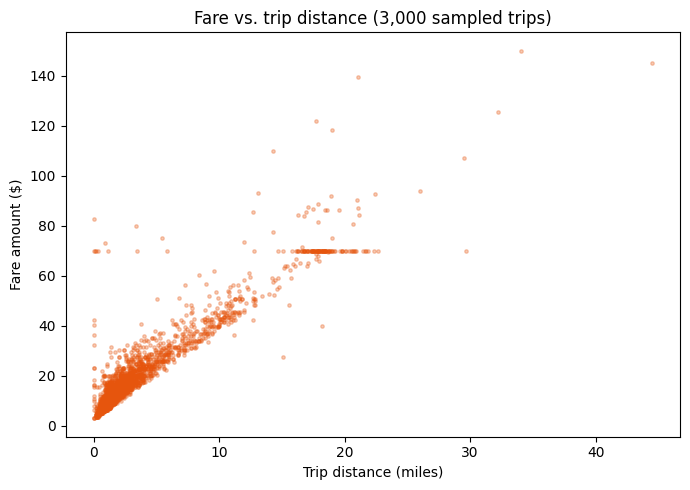

In [19]:
sample = clean.sample(3000, random_state=0)

plt.figure(figsize=(7, 5))
plt.scatter(sample["trip_distance"], sample["fare_amount"], s=6, alpha=0.3, color="#e6550d")
plt.title("Fare vs. trip distance (3,000 sampled trips)")
plt.xlabel("Trip distance (miles)")
plt.ylabel("Fare amount ($)")
plt.tight_layout()
plt.show()

## 6. Chronological train, validation and test splits

Both feature tables are sorted by time and sliced into contiguous 80%, 10% and
10% segments. Training sees the earliest rows, validation supports model
selection, and test estimates performance on the latest held-out rows. A random
split would allow future observations to leak into training.

In [20]:
from src.data.splits import time_based_split

def split_inventory(name, frame, time_col):
    parts = time_based_split(frame, time_col, config)
    return pd.DataFrame([
        {
            "problem": name,
            "split": split_name,
            "rows": len(part),
            "first_time": part[time_col].min(),
            "last_time": part[time_col].max(),
        }
        for split_name, part in zip(("train", "validation", "test"), parts)
    ])

split_evidence = pd.concat([
    split_inventory("demand", demand_features, "pickup_hour"),
    split_inventory("fare", fare_features, "tpep_pickup_datetime"),
], ignore_index=True)
split_evidence

,problem,split,rows,first_time,last_time
0,demand,train,116582,2024-03-08 00:00:00,2024-03-27 04:00:00
1,demand,validation,14573,2024-03-27 04:00:00,2024-03-29 14:00:00
2,demand,test,14573,2024-03-29 14:00:00,2024-03-31 23:00:00
3,fare,train,2430400,2024-03-01 00:00:02,2024-03-25 16:26:52
4,fare,validation,303800,2024-03-25 16:26:53,2024-03-28 18:22:25
5,fare,test,303800,2024-03-28 18:22:25,2024-03-31 23:59:59


## 7. Persisted artifacts and downstream consumers

`scripts/run_pipeline.py` executes the same functions and writes these outputs.
The notebook calculates stages in memory for inspection; the pipeline is the
owner of persisted artifacts.

| Stage | Persisted artifact | Row meaning | Main consumer |
|---|---|---|---|
| Raw trips | `data/raw/yellow_tripdata_2024-01.parquet` | One published TLC trip | validation |
| Zone lookup | `data/raw/taxi_zone_lookup.csv` | One TLC zone | analysis/dashboard labels |
| Clean trips | `data/processed/trips_clean.parquet` | One valid trip | fare features + demand aggregation |
| Hourly demand | `data/processed/demand_hourly.parquet` | One pickup zone-hour | demand features + serving history |
| Demand features | `data/features/demand_features.parquet` | One model-ready zone-hour | inspection/splitting |
| Fare features | `data/features/fare_features.parquet` | One model-ready trip | inspection/splitting |
| Demand splits | `data/features/demand_{train,val,test}.parquet` | Chronological model partitions | demand training/evaluation |
| Fare splits | `data/features/fare_{train,val,test}.parquet` | Chronological model partitions | fare training/evaluation |
| Pipeline summary | `data/processed/pipeline_summary.json` | Counts and cleaning evidence | audit/readiness checks |

The demand serving service also reads `data/processed/demand_hourly.parquet` as
recent history for lag and rolling features. Model training reads the split
Parquet files. Human-readable zone names are joined later for reporting; they
are not personal location traces.

In [ ]:
artifact_inventory = [
    config.raw_dir / trip_name,
    config.raw_dir / "taxi_zone_lookup.csv",
    config.processed_dir / "trips_clean.parquet",
    config.processed_dir / "demand_hourly.parquet",
    config.processed_dir / "pipeline_summary.json",
    config.features_dir / "demand_features.parquet",
    config.features_dir / "fare_features.parquet",
] + [
    config.features_dir / f"{problem}_{split}.parquet"
    for problem in ("demand", "fare")
    for split in ("train", "val", "test")
]

pd.DataFrame({
    "path": [str(path.relative_to(ROOT)) for path in artifact_inventory],
    "exists_after_pipeline_run": [path.exists() for path in artifact_inventory],
})

## 8. Lineage checks and limitations

Use these checks to defend the lineage rather than merely showing files:

1. Clean rows must not exceed raw rows; the cleaning report explains removals.
2. Demand has exactly one row for every observed pickup-zone/hour combination
   after densification.
3. Fare feature rows equal clean trip rows; no aggregation occurs.
4. Lag and rolling demand features use prior observations within the same zone.
5. Train time ends no later than validation time; validation ends no later than
   test time.

Interpretation limits: this is one month of Yellow Taxi data, not Green Taxi or
FHV data; zone IDs are coarse geography; no rider/driver demographics or exact
GPS coordinates are present; cleaning bounds encode assumptions; and one month
cannot represent annual seasonality or long-term change.

In [ ]:
assert len(clean) <= len(raw)
assert len(fare_features) == len(clean)
assert not demand.duplicated(["PULocationID", "pickup_hour"]).any()
for problem in ("demand", "fare"):
    rows = split_evidence[split_evidence["problem"] == problem].set_index("split")
    assert rows.loc["train", "last_time"] <= rows.loc["validation", "first_time"]
    assert rows.loc["validation", "last_time"] <= rows.loc["test", "first_time"]
print("All lineage checks passed.")

## Recap

- Official TLC Parquet and CSV files land in `data/raw/` with their original
    structure preserved.
- Validation applies an explicit schema, period, null and plausibility contract.
- The demand branch changes the grain from one trip to one zone-hour, then adds
    past-only calendar, lag and rolling features.
- The fare branch preserves one row per clean trip and predicts base fare.
- Both branches are split chronologically and persisted for model training.

For your L3 submission, select three findings from different stages and cite the
table, chart or assertion that supports each one.